<a href="https://colab.research.google.com/github/Christy-Roy-tech/Plant_Disease_detection_system/blob/main/corn_disease_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Corn Leaf Disease Classifier (PlantVillage, laptop-accuracy edition)

Run cells **top to bottom**. Only edit the **CONFIG** cell.

Pipeline: dataset layout detection -> data audit -> train/val leakage removal -> class-weighted loss ->
camera-style augmentation -> EfficientNet-B0 two-stage training (frozen warm-up, then full fine-tune) with early stopping on
validation macro-F1 -> temperature calibration -> held-out test report with flip-TTA and a list of misclassified images ->
optional real-camera test -> inference function -> ONNX export.

**Dataset layouts accepted** (inside `DATASET_DIR`):
- `train/<class>/*.jpg` and `val/<class>/*.jpg` (also `valid`/`validation`), **or**
- `<class>/*.jpg` directly (a flat folder; the notebook makes the split itself)

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
!pip install -q onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 87.0 MB/s eta 0:00:00


In [3]:
import os, io, json, random, hashlib, shutil
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay, f1_score

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

print("Torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available())

Torch: 2.11.0+cu130 | CUDA available: True


In [4]:
# ============================== CONFIG - EDIT THESE ==============================
CROP = "Corn"
DATASET_DIR = "/content/drive/MyDrive/corn_dataset"   # folder that holds train/ + val/ OR the class folders
OUTPUT_DIR  = "/content/drive/MyDrive/corn_model"    # checkpoints, best model, plots, ONNX (created if missing)
EXPECTED_NUM_CLASSES = 4                                 # only used for a sanity warning

# OPTIONAL: your own camera photos, laid out as REAL_TEST_DIR/<class_name>/*.jpg (same class names as training)
REAL_TEST_DIR = None

COPY_TO_LOCAL = True        # copy dataset from Drive to Colab's local disk first (much faster epochs)
FLAT_VAL_FRACTION = 0.20    # only used when DATASET_DIR has no train/val split
# =================================================================================

MODEL_NAME      = "efficientnet_b0"   # "efficientnet_b0" (best accuracy/speed), "convnext_tiny" (heavier), "mobilenet_v2" (lightest)
IMG_SIZE        = 224
BATCH_SIZE      = 32
NUM_WORKERS     = 2
NUM_EPOCHS      = 35
WARMUP_EPOCHS   = 3
LR_HEAD         = 1e-3
LR_FINETUNE     = 3e-4
WEIGHT_DECAY    = 1e-4
LABEL_SMOOTHING = 0.1
PATIENCE        = 8

CAMERA_AUG = True            # blur/noise/JPEG to mimic a cheap camera; set False for the cleanest PlantVillage score
DROP_NEAR_DUPLICATES = True  # drop val images that look (almost) identical to a train image
NEAR_DUP_MAX_HAMMING = 5     # out of 256 bits; lower = stricter

CONF_HIGH = 0.85
CONF_LOW  = 0.50

os.makedirs(OUTPUT_DIR, exist_ok=True)
CHECKPOINT_PATH  = f"{OUTPUT_DIR}/checkpoint.pt"
BEST_MODEL_PATH  = f"{OUTPUT_DIR}/best_model.pt"
ONNX_EXPORT_PATH = f"{OUTPUT_DIR}/corn_disease_model.onnx"
LOG_PATH         = f"{OUTPUT_DIR}/train_log.csv"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cuda


### Check 1 - dataset layout, counts, class balance
Look at the printed numbers and sample images before continuing. Fix `DATASET_DIR` if anything looks wrong.

Copying dataset to local disk (one-off, may take a few minutes)...
Using local copy: /content/local_Corn
Layout detected: train/val folders
Classes: ['Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy']
Train counts: {'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 410, 'Corn_(maize)___Common_rust_': 953, 'Corn_(maize)___Northern_Leaf_Blight': 788, 'Corn_(maize)___healthy': 929}
Val counts:   {'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 103, 'Corn_(maize)___Common_rust_': 239, 'Corn_(maize)___Northern_Leaf_Blight': 197, 'Corn_(maize)___healthy': 233}
Class imbalance ratio (largest/smallest): 2.3x -> class-weighted loss will be used


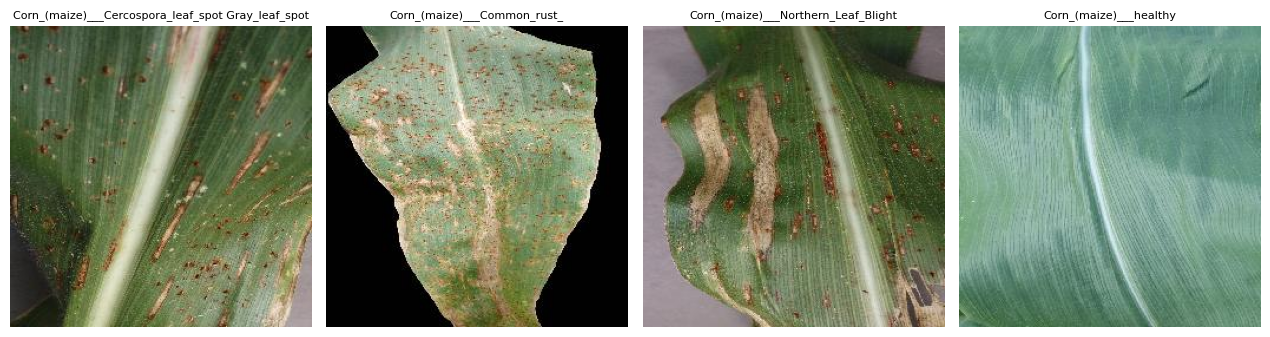

In [5]:
IMG_EXTS = (".jpg", ".jpeg", ".png", ".bmp")

if COPY_TO_LOCAL and DATASET_DIR.startswith("/content/drive"):
    local_dir = f"/content/local_{CROP}"
    if not os.path.exists(local_dir):
        print("Copying dataset to local disk (one-off, may take a few minutes)...")
        shutil.copytree(DATASET_DIR, local_dir)
    DATASET_DIR = local_dir
    print("Using local copy:", DATASET_DIR)

def sub_dirs(root):
    return sorted([d for d in Path(root).iterdir() if d.is_dir() and not d.name.startswith(".")])

def has_images(d):
    return any(p.suffix.lower() in IMG_EXTS for p in d.iterdir() if p.is_file())

def collect_samples(class_dirs):
    out = []
    for d in class_dirs:
        for p in d.rglob("*"):
            if p.is_file() and p.suffix.lower() in IMG_EXTS:
                out.append((p, d.name))
    return out

root = Path(DATASET_DIR)
names = {d.name.lower(): d for d in sub_dirs(root)}
tr_dir = next((names[n] for n in ("train", "training") if n in names), None)
va_dir = next((names[n] for n in ("val", "valid", "validation") if n in names), None)

if tr_dir and va_dir:
    LAYOUT_MODE = "train/val folders"
    train_class_dirs = [d for d in sub_dirs(tr_dir) if has_images(d) or any(d.rglob("*.*"))]
    val_class_dirs   = [d for d in sub_dirs(va_dir) if has_images(d) or any(d.rglob("*.*"))]
    CLASS_NAMES = [d.name for d in train_class_dirs]
    train_raw = collect_samples(train_class_dirs)
    val_raw   = [(p, c) for p, c in collect_samples(val_class_dirs) if c in CLASS_NAMES]
else:
    LAYOUT_MODE = "flat class folders (auto split)"
    class_dirs = [d for d in sub_dirs(root) if any(d.rglob("*.*"))]
    CLASS_NAMES = [d.name for d in class_dirs]
    all_raw = collect_samples(class_dirs)
    rng = random.Random(SEED)
    train_raw, val_raw = [], []
    for c in CLASS_NAMES:
        items = [s for s in all_raw if s[1] == c]
        rng.shuffle(items)
        k = int(round(len(items) * FLAT_VAL_FRACTION))
        val_raw.extend(items[:k]); train_raw.extend(items[k:])

print("Layout detected:", LAYOUT_MODE)
print("Classes:", CLASS_NAMES)
if len(CLASS_NAMES) != EXPECTED_NUM_CLASSES:
    print(f"WARNING: expected {EXPECTED_NUM_CLASSES} classes but found {len(CLASS_NAMES)} - check DATASET_DIR.")

train_counts = {c: sum(1 for _, k in train_raw if k == c) for c in CLASS_NAMES}
val_counts   = {c: sum(1 for _, k in val_raw if k == c) for c in CLASS_NAMES}
print("Train counts:", train_counts)
print("Val counts:  ", val_counts)
ratio = max(train_counts.values()) / max(1, min(train_counts.values()))
print(f"Class imbalance ratio (largest/smallest): {ratio:.1f}x -> class-weighted loss will be used")

n = len(CLASS_NAMES)
cols = min(n, 5); rows = (n + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(3.2 * cols, 3.4 * rows))
axes = np.array(axes).flatten()
for ax in axes: ax.axis("off")
for ax, c in zip(axes, CLASS_NAMES):
    p = next(p for p, k in train_raw if k == c)
    ax.imshow(Image.open(p).convert("RGB")); ax.set_title(c, fontsize=8)
plt.tight_layout(); plt.show()

### Check 2 - data audit (corrupt, unreadable or tiny images)
Bad files are listed and excluded automatically, so they can't crash training halfway through.

In [6]:
def audit(samples, min_side=64):
    good, bad, sizes = [], [], []
    for p, c in samples:
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                w, h = im.size
            if min(w, h) < min_side:
                bad.append((p, "too small")); continue
            sizes.append((w, h)); good.append((p, c))
        except Exception as e:
            bad.append((p, f"unreadable: {e}"))
    return good, bad, sizes

train_ok, train_bad, train_sizes = audit(train_raw)
val_ok,   val_bad,   val_sizes   = audit(val_raw)

print(f"Train: {len(train_ok)} ok, {len(train_bad)} excluded | Val: {len(val_ok)} ok, {len(val_bad)} excluded")
for p, why in (train_bad + val_bad)[:10]:
    print("  excluded:", p, "->", why)
if train_sizes:
    ws, hs = zip(*train_sizes)
    print(f"Train image size: width {min(ws)}-{max(ws)}, height {min(hs)}-{max(hs)} (median {int(np.median(ws))}x{int(np.median(hs))})")

Train: 3080 ok, 0 excluded | Val: 772 ok, 0 excluded
Train image size: width 256-256, height 256-256 (median 256x256)


### Check 3 - train/val leakage
PlantVillage has many photos of the same leaf and many augmented copies. Duplicates between train and val inflate accuracy.
This cell finds exact duplicates (file hash) and near-duplicates (16x16 average hash) and removes them from **val**.
It cannot catch rotated/flipped copies or other photos of the same leaf, so even the cleaned score is somewhat optimistic.

In [7]:
def file_md5(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        h.update(f.read())
    return h.hexdigest()

def ahash256(p):
    with Image.open(p) as im:
        a = np.asarray(im.convert("L").resize((16, 16), Image.BILINEAR), dtype=np.float32)
    return (a > a.mean()).flatten()

train_md5 = {file_md5(p) for p, _ in train_ok}
train_hash = np.stack([ahash256(p) for p, _ in train_ok])

val_clean, exact_dups, near_dups = [], 0, 0
for p, c in val_ok:
    if file_md5(p) in train_md5:
        exact_dups += 1; continue
    if DROP_NEAR_DUPLICATES:
        dist = (train_hash != ahash256(p)).sum(axis=1).min()
        if dist <= NEAR_DUP_MAX_HAMMING:
            near_dups += 1; continue
    val_clean.append((p, c))

print(f"Val images: {len(val_ok)} -> {len(val_clean)} after removing {exact_dups} exact and {near_dups} near duplicates")
if len(val_ok) and (exact_dups + near_dups) / len(val_ok) > 0.30:
    print("NOTE: >30% of val dropped. If too aggressive, lower NEAR_DUP_MAX_HAMMING or set DROP_NEAR_DUPLICATES=False.")

val_counts_clean = {c: sum(1 for _, k in val_clean if k == c) for c in CLASS_NAMES}
print("Val counts after cleaning:", val_counts_clean)
if min(val_counts_clean.values()) < 20:
    print("WARNING: some class has <20 clean val images - its metrics will be noisy. Consider DROP_NEAR_DUPLICATES=False or a larger FLAT_VAL_FRACTION.")

Val images: 772 -> 771 after removing 0 exact and 1 near duplicates
Val counts after cleaning: {'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 103, 'Corn_(maize)___Common_rust_': 239, 'Corn_(maize)___Northern_Leaf_Blight': 197, 'Corn_(maize)___healthy': 232}


### Data pipeline: augmentation, split, class weights
`val_clean` is split 50/50 per class (fixed seed) into a validation set (picks the best epoch, fits calibration) and a held-out
test set (used once at the end).

Train: 3080 | Val: 384 | Test: 387
Class weights: {'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 1.878, 'Corn_(maize)___Common_rust_': 0.808, 'Corn_(maize)___Northern_Leaf_Blight': 0.977, 'Corn_(maize)___healthy': 0.829}


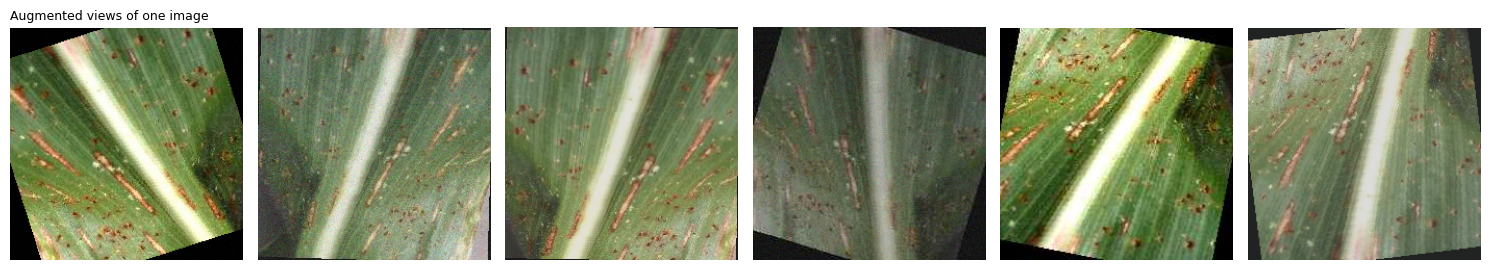

In [8]:
class RandomJPEG:
    def __init__(self, p=0.4, quality=(35, 90)):
        self.p, self.quality = p, quality
    def __call__(self, img):
        if random.random() > self.p:
            return img
        buf = io.BytesIO()
        img.save(buf, format="JPEG", quality=random.randint(*self.quality))
        buf.seek(0)
        return Image.open(buf).convert("RGB")

class RandomGaussianNoise:
    def __init__(self, p=0.3, max_sigma=0.05):
        self.p, self.max_sigma = p, max_sigma
    def __call__(self, t):
        if random.random() > self.p:
            return t
        return (t + torch.randn_like(t) * random.uniform(0.0, self.max_sigma)).clamp(0, 1)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

aug = [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03),
]
if CAMERA_AUG:
    aug += [transforms.RandomApply([transforms.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.2), RandomJPEG(p=0.4)]
aug += [transforms.ToTensor()]
if CAMERA_AUG:
    aug += [RandomGaussianNoise(p=0.3)]
aug += [transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)]
train_transform = transforms.Compose(aug)

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

class LeafDataset(Dataset):
    def __init__(self, samples, class_to_idx, transform):
        self.samples, self.class_to_idx, self.transform = samples, class_to_idx, transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        p, c = self.samples[idx]
        return self.transform(Image.open(p).convert("RGB")), self.class_to_idx[c]

class_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

g = torch.Generator().manual_seed(SEED)
val_samples, test_samples = [], []
for cname in CLASS_NAMES:
    items = [s for s in val_clean if s[1] == cname]
    perm = torch.randperm(len(items), generator=g).tolist()
    half = len(items) // 2
    val_samples.extend(items[i] for i in perm[:half])
    test_samples.extend(items[i] for i in perm[half:])
train_samples = train_ok

train_ds = LeafDataset(train_samples, class_to_idx, train_transform)
val_ds   = LeafDataset(val_samples,   class_to_idx, eval_transform)
test_ds  = LeafDataset(test_samples,  class_to_idx, eval_transform)

pin = DEVICE.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=pin, drop_last=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}")

counts = np.array([sum(1 for _, c in train_samples if c == k) for k in CLASS_NAMES], dtype=np.float32)
class_weights = torch.tensor(counts.sum() / (len(counts) * counts), dtype=torch.float32).to(DEVICE)
print("Class weights:", {c: round(float(w), 3) for c, w in zip(CLASS_NAMES, class_weights.cpu())})

mean_t = torch.tensor(IMAGENET_MEAN).view(3, 1, 1); std_t = torch.tensor(IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
sample_img = Image.open(train_samples[0][0]).convert("RGB")
for ax in axes:
    t = train_transform(sample_img) * std_t + mean_t
    ax.imshow(t.permute(1, 2, 0).clamp(0, 1).numpy()); ax.axis("off")
axes[0].set_title("Augmented views of one image", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

In [9]:
def build_backbone(name):
    if name == "efficientnet_b0":
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1); return m.features, 1280
    if name == "convnext_tiny":
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1); return m.features, 768
    if name == "mobilenet_v2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1); return m.features, m.last_channel
    raise ValueError(f"Unknown MODEL_NAME {name}")

class DiseaseModel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.features, ch = build_backbone(MODEL_NAME)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)
        self.classifier = nn.Linear(ch, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.classifier(self.dropout(x))

def set_backbone_trainable(m, trainable):
    for p in m.features.parameters():
        p.requires_grad = trainable

model = DiseaseModel(num_classes=len(CLASS_NAMES)).to(DEVICE)
train_criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=LABEL_SMOOTHING)
eval_criterion  = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW([
    {"params": model.features.parameters(),   "lr": LR_FINETUNE},
    {"params": model.classifier.parameters(), "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
print(MODEL_NAME, "| parameters:", sum(p.numel() for p in model.parameters()) // 1000, "k")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 175MB/s]

efficientnet_b0 | parameters: 4012 k


### Resume support
If Colab disconnects, re-run the notebook from the top; this cell restores the last completed epoch from `OUTPUT_DIR`.

In [10]:
start_epoch, best_f1, best_loss, epochs_no_improve, history = 0, -1.0, float("inf"), 0, []

if os.path.exists(CHECKPOINT_PATH):
    ckpt = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
    if ckpt.get("class_names") != CLASS_NAMES or ckpt.get("model_name") != MODEL_NAME:
        print("WARNING: checkpoint classes/model differ from current setup - delete checkpoint.pt to start fresh.")
    else:
        model.load_state_dict(ckpt["model_state"])
        optimizer.load_state_dict(ckpt["optimizer_state"])
        scheduler.load_state_dict(ckpt["scheduler_state"])
        start_epoch = ckpt["epoch"]
        best_f1 = ckpt["best_f1"]
        best_loss = ckpt.get("best_loss", float("inf"))
        epochs_no_improve = ckpt.get("epochs_no_improve", 0)
        history = ckpt.get("history", [])
        print(f"Resumed from epoch {start_epoch} (best val macro-F1 {best_f1:.4f})")
else:
    print("No checkpoint found - starting fresh.")

No checkpoint found - starting fresh.


### Training with live per-epoch proof
Epochs 1-`WARMUP_EPOCHS`: backbone frozen, only the head learns. After that everything is fine-tuned. The best model is chosen by
**validation macro-F1** (ties broken by lower val loss). Training stops early after `PATIENCE` epochs without improvement.

In [11]:
@torch.no_grad()
def evaluate(loader, tta=False):
    model.eval()
    all_logits, all_labels = [], []
    for images, labels in loader:
        images = images.to(DEVICE)
        out = model(images)
        if tta:
            out = (out + model(torch.flip(images, dims=[3]))) / 2
        all_logits.append(out.cpu()); all_labels.append(labels)
    logits = torch.cat(all_logits); labels = torch.cat(all_labels)
    loss = eval_criterion(logits, labels).item()
    preds = logits.argmax(1)
    acc = (preds == labels).float().mean().item()
    macro_f1 = f1_score(labels.numpy(), preds.numpy(), average="macro")
    return loss, acc, macro_f1, logits, labels

if not os.path.exists(LOG_PATH):
    with open(LOG_PATH, "w") as f:
        f.write("epoch,train_loss,train_acc,val_loss,val_acc,val_macro_f1\n")

for epoch in range(start_epoch, NUM_EPOCHS):
    frozen = epoch < WARMUP_EPOCHS
    set_backbone_trainable(model, not frozen)
    model.train()
    if frozen:
        model.features.eval()   # keep pretrained BatchNorm statistics untouched during warm-up

    running_loss, correct, total = 0.0, 0, 0
    for images, labels in train_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=(DEVICE.type == "cuda")):
            outputs = model(images)
            loss = train_criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += images.size(0)

    scheduler.step()
    train_loss, train_acc = running_loss / total, correct / total
    val_loss, val_acc, val_f1, _, _ = evaluate(val_loader)

    stage = "warm-up (head only)" if frozen else "fine-tune"
    print(f"Epoch {epoch+1}/{NUM_EPOCHS} [{stage}] | train_loss {train_loss:.4f} acc {train_acc:.4f} "
          f"| val_loss {val_loss:.4f} acc {val_acc:.4f} macro-F1 {val_f1:.4f}")

    history.append({"epoch": epoch + 1, "train_loss": train_loss, "train_acc": train_acc,
                    "val_loss": val_loss, "val_acc": val_acc, "val_f1": val_f1})
    with open(LOG_PATH, "a") as f:
        f.write(f"{epoch+1},{train_loss:.4f},{train_acc:.4f},{val_loss:.4f},{val_acc:.4f},{val_f1:.4f}\n")

    if not frozen:
        improved = (val_f1 > best_f1 + 1e-9) or (abs(val_f1 - best_f1) <= 1e-9 and val_loss < best_loss)
        if improved:
            best_f1, best_loss, epochs_no_improve = val_f1, val_loss, 0
            torch.save(model.state_dict(), BEST_MODEL_PATH)
            print(f"  -> new best val macro-F1 {val_f1:.4f}, saved")
        else:
            epochs_no_improve += 1

    torch.save({"epoch": epoch + 1, "model_state": model.state_dict(), "optimizer_state": optimizer.state_dict(),
                "scheduler_state": scheduler.state_dict(), "best_f1": best_f1, "best_loss": best_loss,
                "epochs_no_improve": epochs_no_improve, "history": history,
                "class_names": CLASS_NAMES, "model_name": MODEL_NAME}, CHECKPOINT_PATH)

    if epochs_no_improve >= PATIENCE:
        print(f"Early stopping: no improvement for {PATIENCE} epochs.")
        break

if not os.path.exists(BEST_MODEL_PATH):
    torch.save(model.state_dict(), BEST_MODEL_PATH)
print("\nTraining finished.")

Epoch 1/35 [warm-up (head only)] | train_loss 0.7472 acc 0.8490 | val_loss 0.3100 acc 0.9297 macro-F1 0.9057
Epoch 2/35 [warm-up (head only)] | train_loss 0.5988 acc 0.9173 | val_loss 0.2712 acc 0.9375 macro-F1 0.9093
Epoch 3/35 [warm-up (head only)] | train_loss 0.5781 acc 0.9326 | val_loss 0.2688 acc 0.9323 macro-F1 0.9037
Epoch 4/35 [fine-tune] | train_loss 0.6040 acc 0.9189 | val_loss 0.1837 acc 0.9714 macro-F1 0.9601
  -> new best val macro-F1 0.9601, saved
Epoch 5/35 [fine-tune] | train_loss 0.5020 acc 0.9609 | val_loss 0.1778 acc 0.9688 macro-F1 0.9582
Epoch 6/35 [fine-tune] | train_loss 0.4721 acc 0.9727 | val_loss 0.1935 acc 0.9688 macro-F1 0.9569
Epoch 7/35 [fine-tune] | train_loss 0.4651 acc 0.9736 | val_loss 0.1503 acc 0.9792 macro-F1 0.9722
  -> new best val macro-F1 0.9722, saved
Epoch 8/35 [fine-tune] | train_loss 0.4553 acc 0.9759 | val_loss 0.1887 acc 0.9688 macro-F1 0.9582
Epoch 9/35 [fine-tune] | train_loss 0.4363 acc 0.9821 | val_loss 0.1624 acc 0.9740 macro-F1 0.96

### Proof - training curves
Train and validation lines should move together. A growing gap means overfitting.

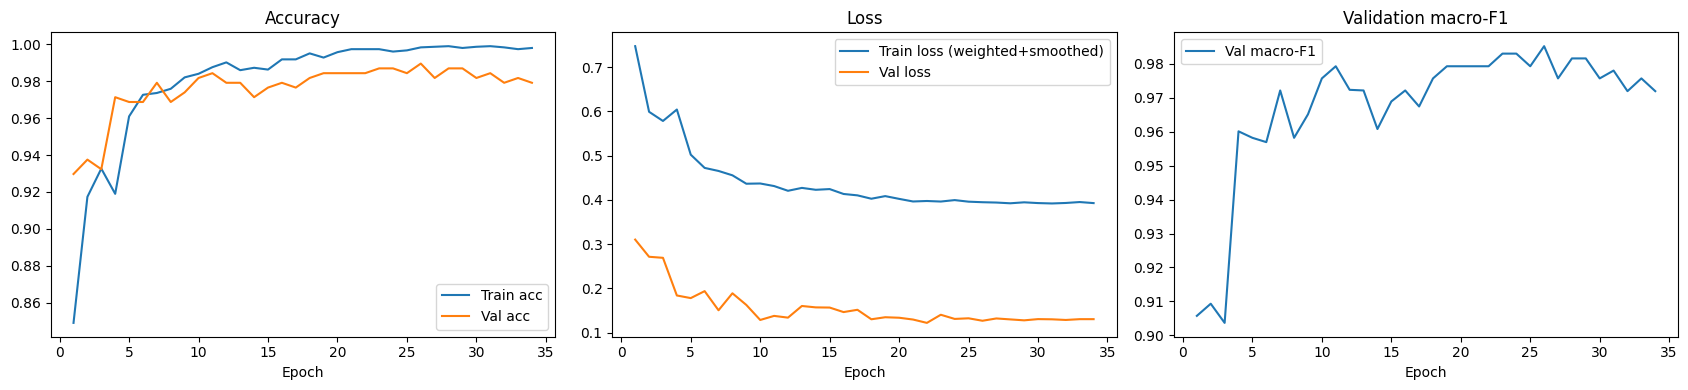

In [12]:
ep = [h["epoch"] for h in history]
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(ep, [h["train_acc"] for h in history], label="Train acc")
axes[0].plot(ep, [h["val_acc"] for h in history], label="Val acc")
axes[0].set_title("Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].plot(ep, [h["train_loss"] for h in history], label="Train loss (weighted+smoothed)")
axes[1].plot(ep, [h["val_loss"] for h in history], label="Val loss")
axes[1].set_title("Loss"); axes[1].set_xlabel("Epoch"); axes[1].legend()
axes[2].plot(ep, [h["val_f1"] for h in history], label="Val macro-F1")
axes[2].set_title("Validation macro-F1"); axes[2].set_xlabel("Epoch"); axes[2].legend()
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/training_curves.png", dpi=150); plt.show()

### Confidence calibration (temperature scaling)
Fits one temperature `T` on the validation set so reported confidence is closer to real accuracy. It does not change which class wins.

In [13]:
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.eval()

_, _, _, val_logits, val_labels = evaluate(val_loader)

temperature = nn.Parameter(torch.ones(1))
opt = torch.optim.LBFGS([temperature], lr=0.05, max_iter=200)
def closure():
    opt.zero_grad()
    loss = F.cross_entropy(val_logits / temperature.clamp(min=0.05), val_labels)
    loss.backward()
    return loss

nll_before = F.cross_entropy(val_logits, val_labels).item()
opt.step(closure)
TEMPERATURE = float(temperature.clamp(min=0.05).item())
nll_after = F.cross_entropy(val_logits / TEMPERATURE, val_labels).item()
print(f"Temperature T = {TEMPERATURE:.3f} | val NLL before {nll_before:.4f} -> after {nll_after:.4f}")

Temperature T = 0.496 | val NLL before 0.1266 -> after 0.0451


### Proof - held-out test set
Images never used for training, epoch selection or calibration. Flip test-time augmentation (TTA) is used for the headline number.

TEST accuracy 0.9897 (no TTA 0.9897) | macro-F1 0.9850 | 4 errors out of 387
                                                    precision    recall  f1-score   support

Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     1.0000    0.9231    0.9600        52
                       Corn_(maize)___Common_rust_     1.0000    1.0000    1.0000       120
               Corn_(maize)___Northern_Leaf_Blight     0.9612    1.0000    0.9802        99
                            Corn_(maize)___healthy     1.0000    1.0000    1.0000       116

                                          accuracy                         0.9897       387
                                         macro avg     0.9903    0.9808    0.9850       387
                                      weighted avg     0.9901    0.9897    0.9896       387



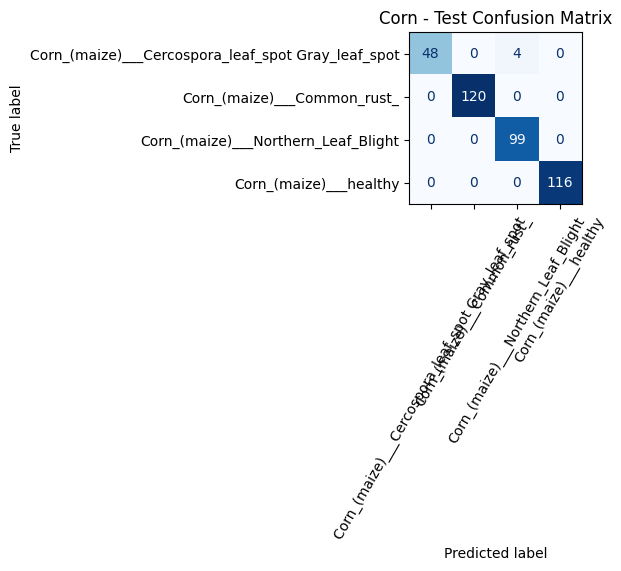

Mean calibrated confidence 0.992 vs actual accuracy 0.990 (should be close)
  confidence 0.50-0.85: 3 images, accuracy 0.333
  confidence 0.85-1.00: 384 images, accuracy 0.995


In [14]:
test_loss, test_acc_plain, _, _, _ = evaluate(test_loader, tta=False)
_, test_acc, test_f1, test_logits, test_labels = evaluate(test_loader, tta=True)
preds = test_logits.argmax(1).numpy(); true = test_labels.numpy()

print(f"TEST accuracy {test_acc:.4f} (no TTA {test_acc_plain:.4f}) | macro-F1 {test_f1:.4f} | {int((preds != true).sum())} errors out of {len(true)}")
print(classification_report(true, preds, target_names=CLASS_NAMES, digits=4, labels=list(range(len(CLASS_NAMES))), zero_division=0))

cm = confusion_matrix(true, preds, labels=list(range(len(CLASS_NAMES))))
s = max(6, 0.7 * len(CLASS_NAMES))
fig, ax = plt.subplots(figsize=(s, s))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=60)
ax.set_title(f"{CROP} - Test Confusion Matrix")
plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/confusion_matrix.png", dpi=150); plt.show()

probs = F.softmax(test_logits / TEMPERATURE, dim=1)
conf = probs.max(1).values.numpy()
print(f"Mean calibrated confidence {conf.mean():.3f} vs actual accuracy {test_acc:.3f} (should be close)")
for lo, hi in [(0.0, CONF_LOW), (CONF_LOW, CONF_HIGH), (CONF_HIGH, 1.01)]:
    m = (conf >= lo) & (conf < hi)
    if m.sum():
        print(f"  confidence {lo:.2f}-{min(hi,1.0):.2f}: {m.sum()} images, accuracy {(preds[m] == true[m]).mean():.3f}")

### Proof - the mistakes
Every misclassified test image (up to 12). Often these are mislabeled files or near-identical classes, which tells you whether more accuracy is even possible.

4 misclassified test images


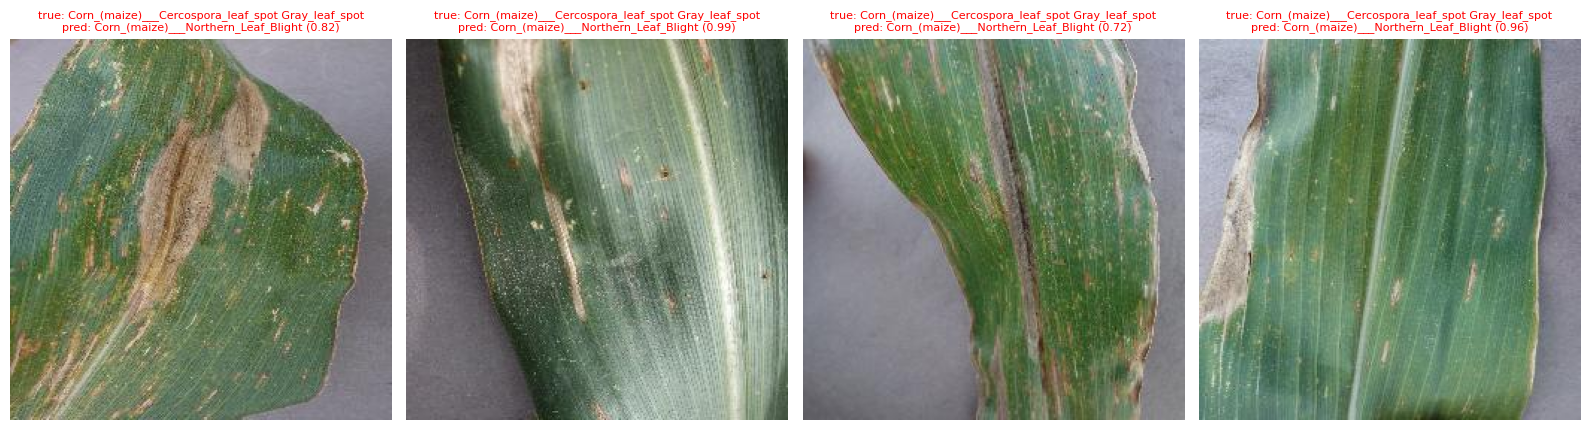

In [15]:
wrong = np.where(preds != true)[0]
print(f"{len(wrong)} misclassified test images")
if len(wrong):
    show = wrong[:12]
    cols = min(4, len(show)); rows = (len(show) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4.2 * rows))
    axes = np.array(axes).flatten()
    for ax in axes: ax.axis("off")
    for ax, i in zip(axes, show):
        p, _ = test_samples[i]
        ax.imshow(Image.open(p).convert("RGB"))
        ax.set_title(f"true: {CLASS_NAMES[true[i]]}\npred: {CLASS_NAMES[preds[i]]} ({conf[i]:.2f})", fontsize=8, color="red")
    plt.tight_layout(); plt.show()

### Proof - your real camera (the honest number)
Set `REAL_TEST_DIR` in CONFIG to a folder of your own photos organised as `REAL_TEST_DIR/<class_name>/*.jpg`. Expect it to be
lower than the PlantVillage number; that gap is the real finding.

In [16]:
if REAL_TEST_DIR and os.path.isdir(REAL_TEST_DIR):
    real_dirs = [d for d in sub_dirs(REAL_TEST_DIR) if d.name in CLASS_NAMES]
    real_ok, real_bad, _ = audit(collect_samples(real_dirs))
    print(f"Real-camera images: {len(real_ok)} usable, {len(real_bad)} excluded")
    real_ds = LeafDataset(real_ok, class_to_idx, eval_transform)
    real_loader = DataLoader(real_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    _, real_acc, real_f1, real_logits, real_labels = evaluate(real_loader, tta=True)
    rp, rt = real_logits.argmax(1).numpy(), real_labels.numpy()
    print(f"REAL CAMERA accuracy {real_acc:.4f} | macro-F1 {real_f1:.4f}   (PlantVillage test: {test_acc:.4f})")
    print(classification_report(rt, rp, target_names=CLASS_NAMES, digits=4, labels=list(range(len(CLASS_NAMES))), zero_division=0))
    s = max(6, 0.7 * len(CLASS_NAMES))
    fig, ax = plt.subplots(figsize=(s, s))
    ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(rt, rp, labels=list(range(len(CLASS_NAMES)))),
                           display_labels=CLASS_NAMES).plot(ax=ax, cmap="Oranges", colorbar=False, xticks_rotation=60)
    ax.set_title("Real-camera Confusion Matrix")
    plt.tight_layout(); plt.savefig(f"{OUTPUT_DIR}/confusion_matrix_real_camera.png", dpi=150); plt.show()
else:
    print("REAL_TEST_DIR not set - skipped.")

REAL_TEST_DIR not set - skipped.


### Inference function (thresholds + flip averaging + multi-frame averaging)
`predict_leaf` takes one or several PIL images of the same leaf, averages calibrated probabilities (each frame plus its mirror), and returns
`confident` (>= `CONF_HIGH`), `uncertain_retake` (between thresholds) or `unknown` (< `CONF_LOW`).
This model only knows the classes of one crop: run it only after you have confirmed the plant type.

In [17]:
@torch.no_grad()
def predict_leaf(pil_images):
    if not isinstance(pil_images, (list, tuple)):
        pil_images = [pil_images]
    model.eval()
    batch = []
    for im in pil_images:
        t = eval_transform(im.convert("RGB"))
        batch.extend([t, torch.flip(t, dims=[2])])
    logits = model(torch.stack(batch).to(DEVICE)).cpu() / TEMPERATURE
    probs = F.softmax(logits, dim=1).mean(0)
    top = int(probs.argmax())
    c = float(probs[top])
    status = "confident" if c >= CONF_HIGH else ("uncertain_retake" if c >= CONF_LOW else "unknown")
    return {"label": CLASS_NAMES[top], "confidence": round(c, 4), "status": status,
            "all_probs": {n: round(float(p), 4) for n, p in zip(CLASS_NAMES, probs)}}

for p_, c_ in test_samples[:3]:
    print("true:", c_, "->", predict_leaf(Image.open(p_)))

true: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot -> {'label': 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'confidence': 0.9997, 'status': 'confident', 'all_probs': {'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 0.9997, 'Corn_(maize)___Common_rust_': 0.0, 'Corn_(maize)___Northern_Leaf_Blight': 0.0001, 'Corn_(maize)___healthy': 0.0001}}
true: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot -> {'label': 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'confidence': 0.9976, 'status': 'confident', 'all_probs': {'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 0.9976, 'Corn_(maize)___Common_rust_': 0.0003, 'Corn_(maize)___Northern_Leaf_Blight': 0.0015, 'Corn_(maize)___healthy': 0.0006}}
true: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot -> {'label': 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'confidence': 0.9995, 'status': 'confident', 'all_probs': {'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 0.9995, 'Corn_(maize)___Common_rus

### Export to ONNX + deployment config
The ONNX file holds only the network. Class names, temperature, thresholds and preprocessing are in `deploy_config.json`;
your deployment code must apply the same resize/normalize and `logits / temperature` before softmax.

In [19]:
!pip install -q onnx onnxscript onnxruntime
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.eval()
dummy_input = torch.randn(1, 3, IMG_SIZE, IMG_SIZE, device=DEVICE)

export_kwargs = dict(input_names=["image"], output_names=["disease_logits"],
                     dynamic_axes={"image": {0: "batch_size"}, "disease_logits": {0: "batch_size"}},
                     opset_version=17)
try:
    torch.onnx.export(model, dummy_input, ONNX_EXPORT_PATH, dynamo=False, **export_kwargs)
except TypeError:   # older torch without the dynamo argument
    torch.onnx.export(model, dummy_input, ONNX_EXPORT_PATH, **export_kwargs)
print(f"Exported ONNX -> {ONNX_EXPORT_PATH}")

try:
    import onnxruntime as ort
    sess = ort.InferenceSession(ONNX_EXPORT_PATH, providers=["CPUExecutionProvider"])
    onnx_out = sess.run(None, {"image": dummy_input.cpu().numpy()})[0]
    with torch.no_grad():
        torch_out = model(dummy_input).cpu().numpy()
    print(f"Max |PyTorch - ONNX| difference: {abs(onnx_out - torch_out).max():.6f}  (should be ~1e-4 or smaller)")
except ImportError:
    print("pip install onnxruntime to run the parity check.")

deploy_config = {
    "crop": CROP, "model": MODEL_NAME, "class_names": CLASS_NAMES, "img_size": IMG_SIZE,
    "mean": IMAGENET_MEAN, "std": IMAGENET_STD,
    "temperature": TEMPERATURE, "conf_high": CONF_HIGH, "conf_low": CONF_LOW,
    "test_accuracy": round(test_acc, 4), "test_macro_f1": round(float(test_f1), 4),
    "preprocess": "RGB -> resize to (img_size, img_size) -> /255 -> normalize(mean, std) -> NCHW float32",
    "postprocess": "softmax(logits / temperature); average over frames; apply thresholds",
}
with open(f"{OUTPUT_DIR}/deploy_config.json", "w") as f:
    json.dump(deploy_config, f, indent=2)
print(f"Saved deploy config -> {OUTPUT_DIR}/deploy_config.json")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 98.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 192.2/192.2 kB 18.4 MB/s eta 0:00:00


/tmp/ipykernel_1091/1888231201.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy_input, ONNX_EXPORT_PATH, dynamo=False, **export_kwargs)


Exported ONNX -> /content/drive/MyDrive/corn_model/corn_disease_model.onnx
Max |PyTorch - ONNX| difference: 0.000001  (should be ~1e-4 or smaller)
Saved deploy config -> /content/drive/MyDrive/corn_model/deploy_config.json
